In [174]:
# test the 4FGL catalog for covariate shift

In [175]:
import numpy as np
import random
import pandas as pd
from matplotlib import pyplot
from astropy.io import fits
from scipy.stats import binom, kstest
print(np.__version__)

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve
from sklearn.calibration import calibration_curve

from sklearn.mixture import GaussianMixture

import os
import sys
if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

1.24.3


In [176]:
def get_neff(w):
    return np.sum(w)**2/np.sum(w**2)

def AIC(log_probs, nGMM, ndim=10):
    npars = nGMM * (ndim + ndim**2)
    return 2 * npars - 2 * np.sum(log_probs)


In [177]:
if 1:
    import importlib
    importlib.reload(util);


In [178]:
#os.getcwd()

In [179]:
script_fn = 'fermi_multiclass/notebooks/cov_shift/cov_shift_weights.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}

# select the catalog and the case
cat_name = '4FGL-DR4' # '4FGL-DR3'
if cat_name == '4FGL-DR4':
    baseline_case = '4FGL-DR4_GMM_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #case = '4FGL-DR4_GMM_RF_no_coord_no_bcu_spp' # '4FGL-DR4_GMM_RF_no_prune'
    #case = '4FGL-DR4_GMM_RF_no_coord'
    #case = '4FGL-DR4_GMM_RF'
    case = '4FGL-DR4_GMM_RF_no_bcu_spp'
    #baseline_case = '4FGL-DR4_2class_RF' # '4FGL-DR4_GMM_RF', '4FGL-DR4_2class_RF'
    #case = '4FGL-DR4_2class_RF'
    #baseline_case = '4FGL-DR4_GMM_RF_no_coord'
    #case = '4FGL-DR4_GMM_RF_no_coord'
if cat_name == '4FGL-DR3':
    baseline_case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp'
    case = '4FGL-DR3_GMM_RF_no_coord_no_bcu_spp' # '4FGL-DR4_GMM_RF_no_prune'

    
baseline = (case == baseline_case)
root_folder = '../../'
config_folder = root_folder + 'config/'

# generic inputs
cdict = util.get_config_dict(#cat_name=cat_name, 
                             baseline_case=baseline_case, 
                             #baseline_fn=baseline_fn,
                             #cases_fn=cases_fn,
                             case=case, 
                             folder=config_folder)


cdict['root_folder'] = root_folder
folder_in = cdict['root_folder'] + cdict.get('folder_in', 'data_in/')
folder_out = cdict['root_folder'] + cdict.get('folder_out', 'data_out/')
folder = folder_out
Eind = int(cdict.get('Eind', 1000))
class_name = cdict.get('class_name', 'CLASS1')

assoc_sources = cdict.get('assoc_sources', 'all_assoc')
sep_model = cdict.get('sep_model', 'GMM')
#sep_model = 'RF' # 'GMM', 'RF'
nmin = cdict.get('nmin')
if nmin is not None: 
    nmin = int(nmin)
max_depth = int(cdict.get('max_depth', 5))
feature_mode = cdict.get('features', 'all_features')

alg = cdict.get('class_alg', 'RF')
train_weighting = cdict.get('train_weighting')
test_weighting = cdict.get('test_weighting')
weighted = (train_weighting is not None) or (test_weighting is not None)
#oversample_factor = 1 # used for 'resampled' training and testing
max_sample = int(cdict.get('max_sample', 7))
test_frac = float(cdict.get('test_frac', 0.3))
nav = int(cdict.get('nav', 10))
nGMM_base = cdict.get('nGMM_w', 10)

tree_alg = cdict.get('sep_model', 'GMM')
#tree_alg = '2class' # 'stat', 'GMM', 'RF', '4class', '2class', 'RF_aakash'
#cdict['sep_model'] = tree_alg

# input data
tree_cat_fn = util.get_tree_cat_fn(cdict)
tree_cat_dict = dio3.loaddict(tree_cat_fn)
if util.exist_internal(tree_cat_dict):
    util.remove_internal(tree_cat_dict)
cat_tree = list(tree_cat_dict.keys())

xdf_fn = util.get_xdf_fn(cdict)
xdf = pd.read_csv(xdf_fn, index_col=0)
ns = len(xdf)

all_features = [name for name in xdf.columns if name.find('CLASS') == -1]
if feature_mode == 'all_features':
    features = all_features
elif feature_mode == 'no_coord_features':
    features = [feat for feat in all_features if feat.find('GL') == -1]


# specific inputs
#folder = folder_out
#nGMM = 10
nGMM = nGMM_base
cdict['nGMM_w'] = nGMM
save_plots = 0
copy2tex = 0
class1 = '00' # class to plot ROC, precision and recall
lss = ['-', '--', '-.', ':', (0, (5, 4)), (0, (4, 5, 1, 5)), (0, (3, 5, 1, 5, 1, 5))]
markers = ['s', 'o', 'd', '<', '>', 'v', '^']

test_nGMM = False
if test_nGMM:
    nGMMs = np.arange(2, 31, 2)
else:
    nGMMs = [nGMM_base]

if tree_alg == '2class':
    title_dict = {'00': 'Extragalactic', '01': 'Galactic'}

nclasses = len(tree_cat_dict)
max_tree_cat_dict = util.tree2max_tree(tree_cat_dict)
dec_tree_cat_dict = util.max_tree2dec_tree(max_tree_cat_dict)
nodes = [str(key) for key in dec_tree_cat_dict.keys()]

# file to save weights
save_weights = 1
recalculate = 1
weights_fn = util.get_weights_fn(cdict)

plots_folder = root_folder + 'plots/cov_shift_%s_%s/' % (cat_name, feature_mode)
if not os.path.isdir(plots_folder):
    os.mkdir(plots_folder)

if copy2tex:
    paper_folder = '/Users/Dmitry/Work/Fermi/DM_halos/paper1/plots_tmp/'
    plots_folder_paper = paper_folder
    if not os.path.isdir(plots_folder_paper):
        os.makedirs(plots_folder_paper)
    

assoc_classes = []
for cls in tree_cat_dict.values():
    assoc_classes.extend(cls)
nsrc_dict = util.get_nsrc_dict(xdf, class_column=class_name, classes=assoc_classes)
#assoc_classes = list(nsrc_dict.keys())
#nsrc_dict = {cl:np.sum(xdf[class_name] == cl) for cl in assoc_classes}

top_features = features
if tree_alg == 'GMM':
    #top_features = ['LP_SigCurv', 'LP_index1000MeV', 'log10(Variability_Index)',\
    #'log10(Energy_Flux100)', 'log10(Unc_Energy_Flux100)', 'LP_beta',]
    #top_features = ['log10(Unc_Energy_Flux100)', 'LP_beta', 'LP_SigCurv',]
    #top_features = ['log10(Unc_Energy_Flux100)', 'LP_beta', ]
    top_features = features
elif tree_alg == '4class':
    #top_features = ['log10(Unc_Energy_Flux100)', 'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)']
    top_features = features
    
use_features = top_features
#use_features = features
paper_features = ['sin(GLAT)', 'log10(Signif_Avg)', 'log10(Variability_Index)', 'LP_beta']

fig_width = 7  # width in inches
fig_height = 5    # height in inches
fig_size =  [fig_width, fig_height]
fig_pars_dict = {'fig_size': fig_size, 'legend.fontsize':12, 'legend.labelspacing':0.3}
putil.setup_figure_pars(pars_dict=fig_pars_dict)
pyplot.rcParams['legend.labelspacing'] = 0.3

plot_descr = '%s_classif%s_show%s' % (tree_alg, alg, class1)

for key in tree_cat_dict:
    cls = tree_cat_dict[key]
    clf_mask = util.get_cl_mask(cls, xdf, cname=class_name)
    print('%s (%i sources)' % (util.cl_list2str(cls), sum(clf_mask)))
print(use_features)
print(weights_fn)

snr, pwn, sfr, psr, nov, gc, hmb (231 sources)
gal, msp, glc, bin, lmb (238 sources)
css, nlsy1, fsrq (833 sources)
rdg, sbg, bll, agn, ssrq, sey (1565 sources)
['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)', 'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV', 'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)']
../../data_out//weights/weights_4FGL-DR4_no_bcu_spp_all_features_12kernels.csv


In [180]:
weights_fn

'../../data_out//weights/weights_4FGL-DR4_no_bcu_spp_all_features_12kernels.csv'

In [181]:
print(tree_cat_fn)

../../data_out//tree_cat_4FGL-DR4_sep_model_GMM_nmin_100_no_bcu_spp_all_features.yaml


In [182]:
tree_cat_dict

{'000': ['snr', 'pwn', 'sfr', 'psr', 'nov', 'gc', 'hmb'],
 '001': ['gal', 'msp', 'glc', 'bin', 'lmb'],
 '010': ['css', 'nlsy1', 'fsrq'],
 '011': ['rdg', 'sbg', 'bll', 'agn', 'ssrq', 'sey']}

In [183]:
#all_cls = []
clf_masks = {node:util.get_cl_mask(cls, xdf, cname=class_name) for node, cls in tree_cat_dict.items()}
#for cls in tree_cat_dict.values():
#    all_cls.extend(cls)
#clf_mask = util.get_cl_mask(all_cls, xdf, cname=class_name)
clf_mask = util.get_cl_mask(assoc_classes, xdf, cname=class_name)
#unas_mask = (xdf[class_name] == 'unas') | (xdf[class_name] == 'unk') 
unas_mask = ~clf_mask
sum(unas_mask), sum(~unas_mask), sum(clf_mask), len(clf_mask)

(4324, 2867, 2867, 7191)

In [184]:
xdf.columns

Index(['sin(GLAT)', 'cos(GLON)', 'sin(GLON)', 'log10(Energy_Flux100)',
       'log10(Unc_Energy_Flux100)', 'log10(Signif_Avg)', 'LP_index1000MeV',
       'LP_beta', 'LP_SigCurv', 'log10(Variability_Index)', 'CLASS1'],
      dtype='object')

In [185]:
add_Epeak = True
if add_Epeak:
    var_name = 'log10Epeak'
    xlabel = var_name
    inds = xdf['LP_index1000MeV']
    beta = xdf['LP_beta']
    log10Epeak = 0.5 * (2. - inds) / beta
    log10Epeak = np.maximum(-1.1, log10Epeak)
    log10Epeak = np.minimum(2.1, log10Epeak)
    xdf[var_name] = log10Epeak
    xmin, xmax = -1., 2.
    if var_name not in top_features:
        top_features.append(var_name)
lat_mask = True
if lat_mask:
    mask = np.abs(xdf['sin(GLAT)']) > np.sin(np.deg2rad(10.))
else:
    mask = True

In [186]:
label_dict = {'00': 'Egal','01': 'Gal'}

/var/folders/mb/yxqk032n4lvgsvnl3lqzbwvr0000gn/T/ipykernel_16139/1684540528.py:25: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  pyplot.figure()


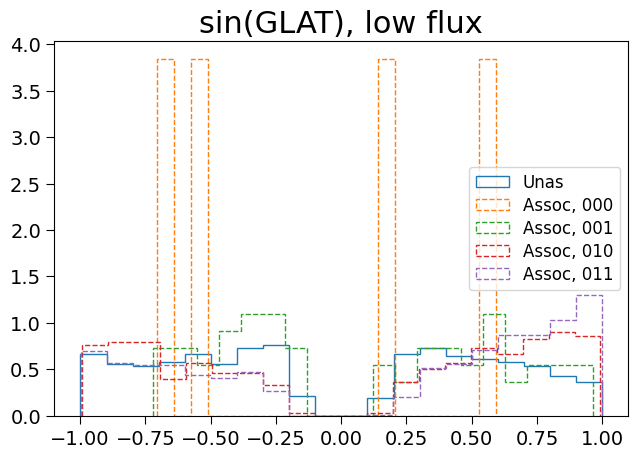

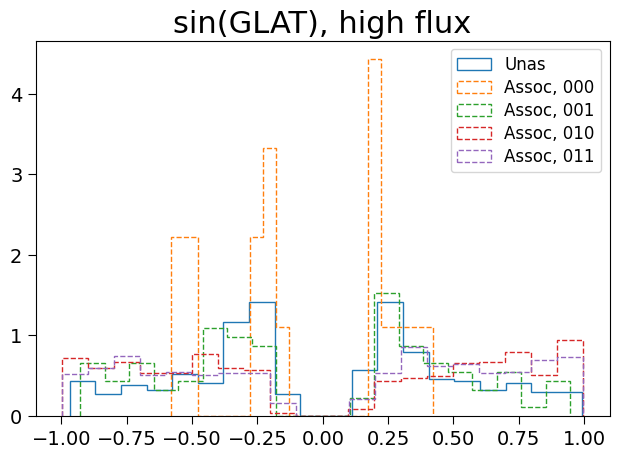

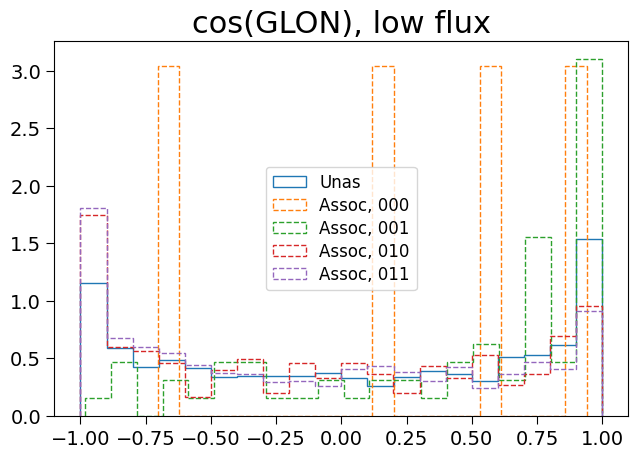

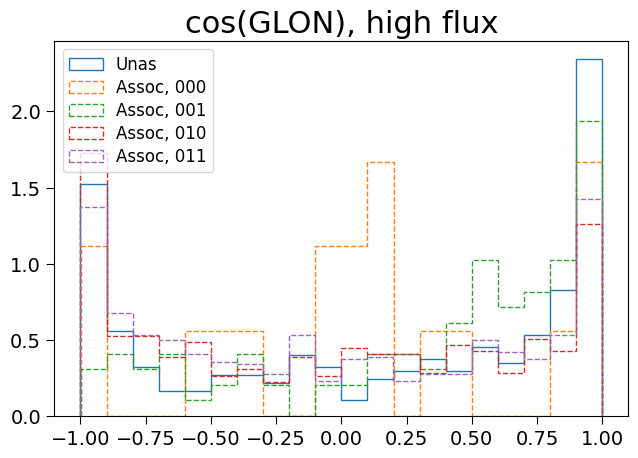

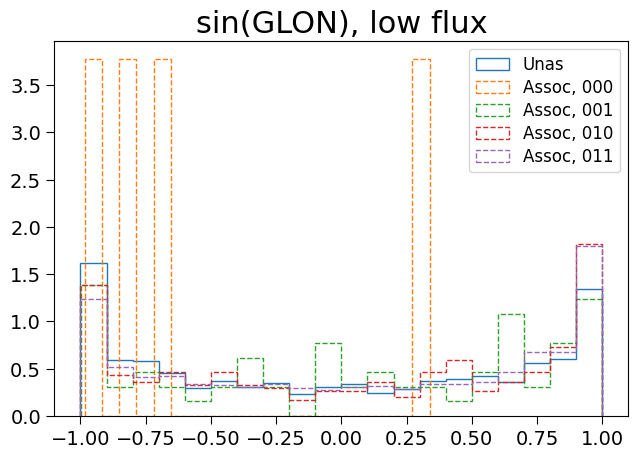

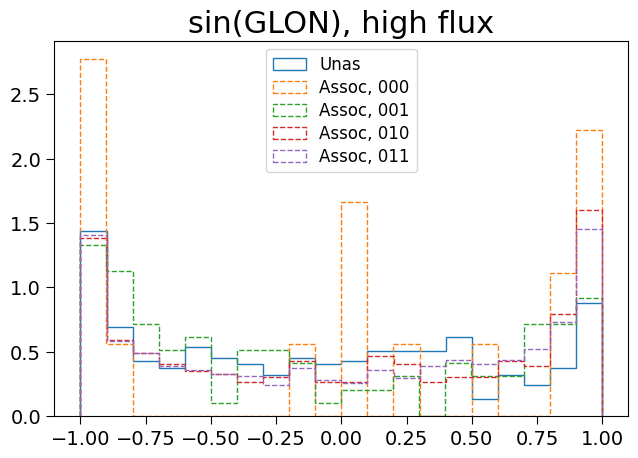

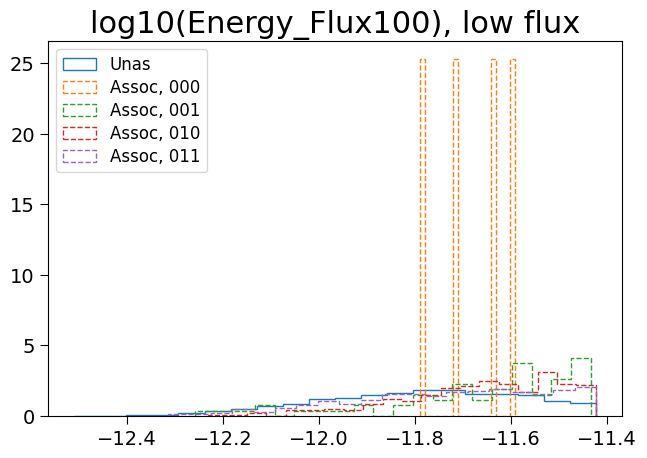

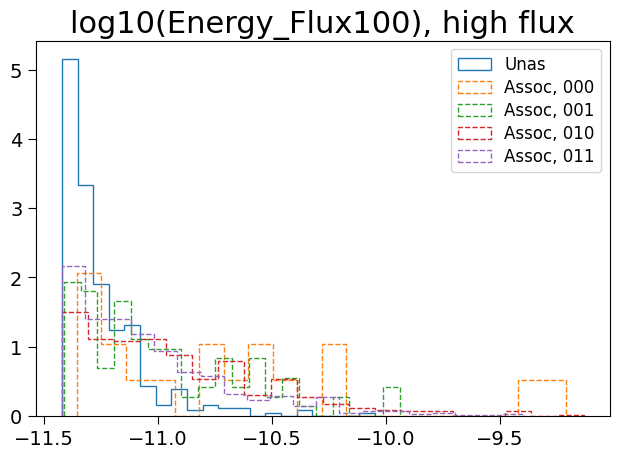

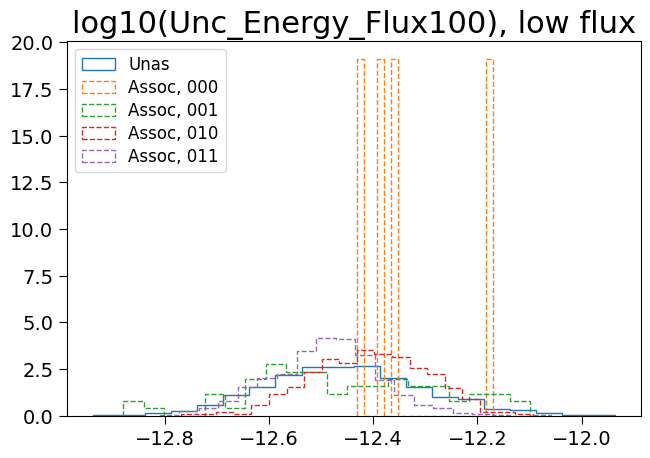

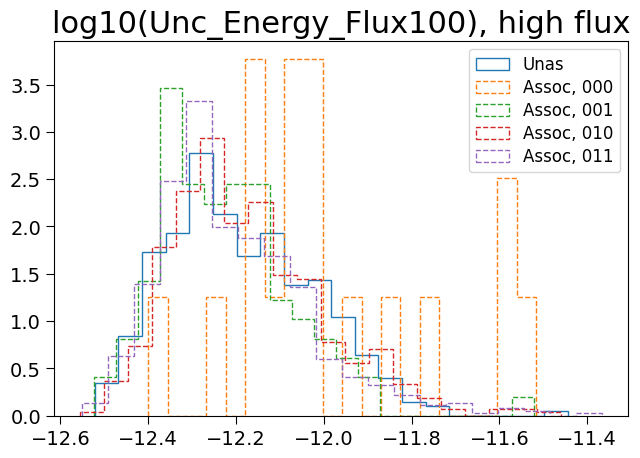

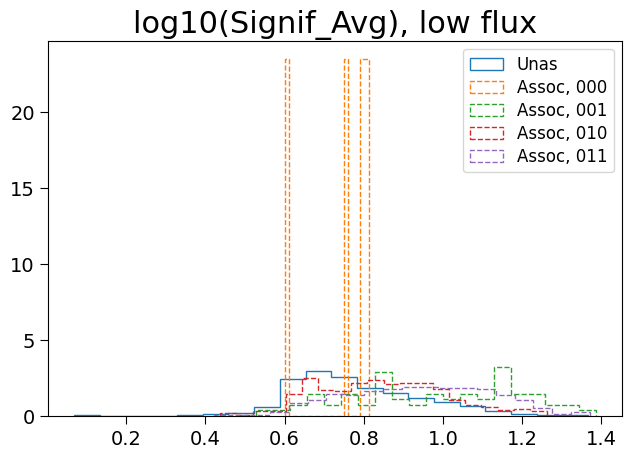

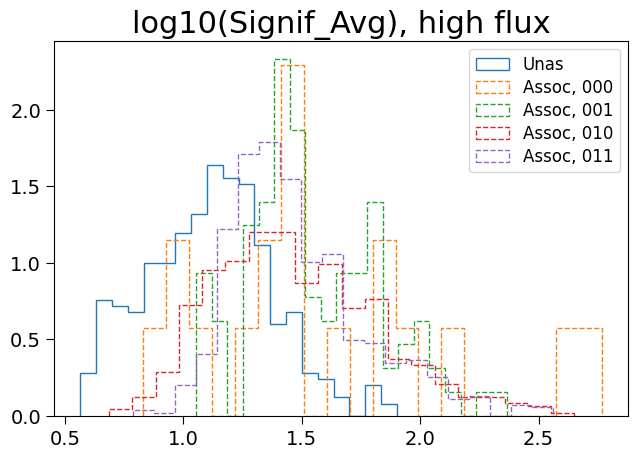

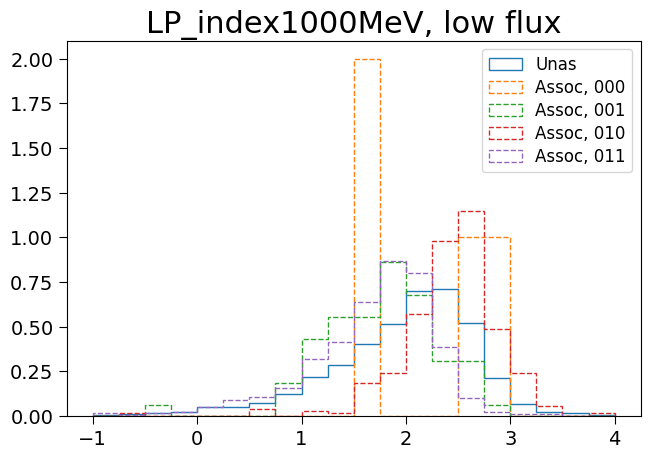

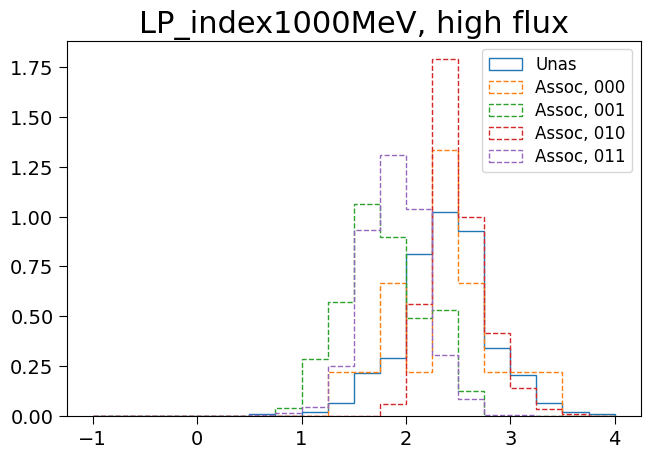

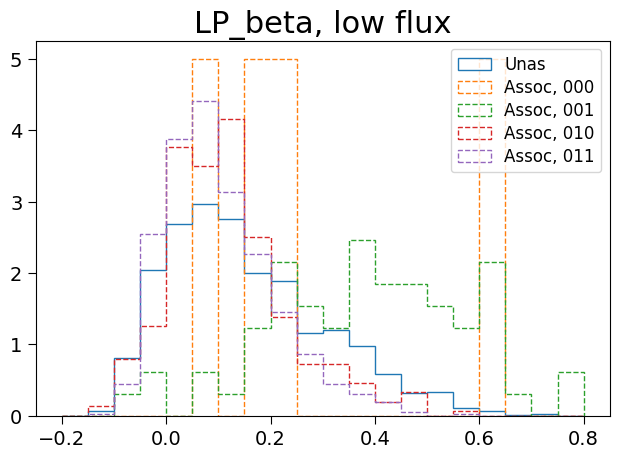

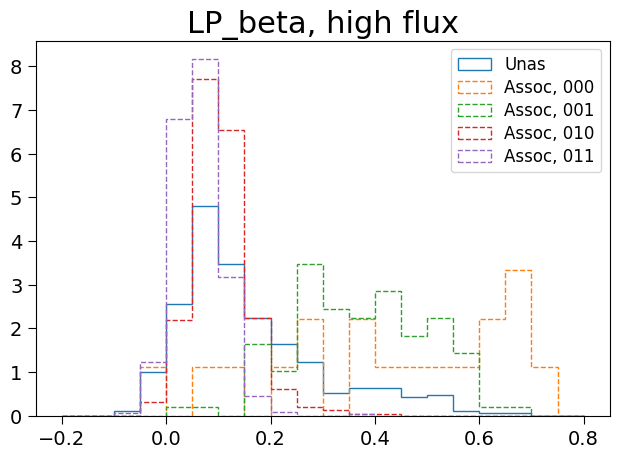

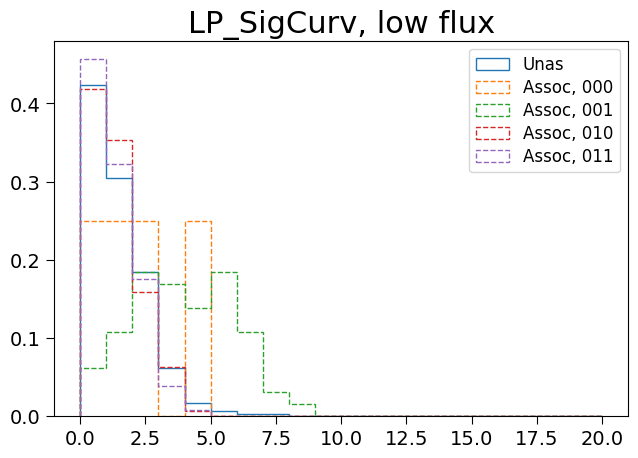

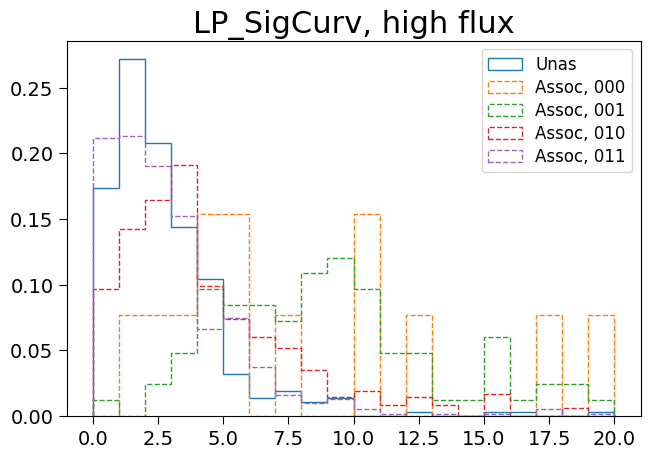

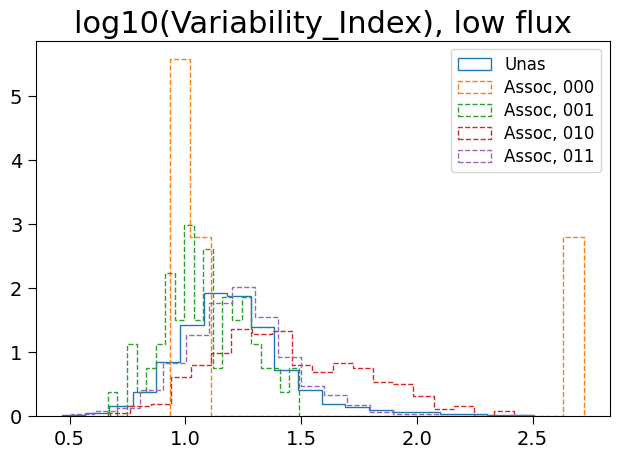

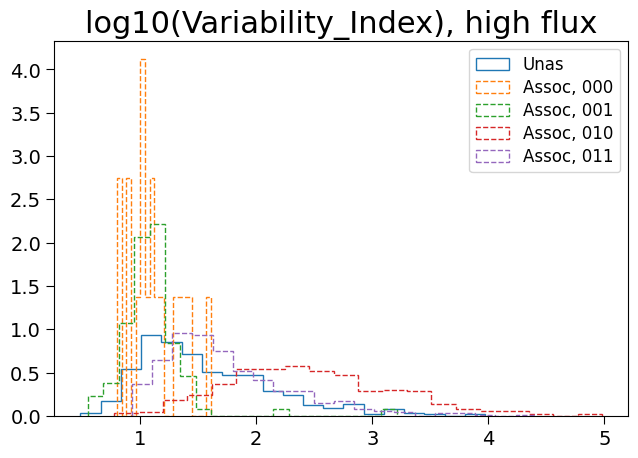

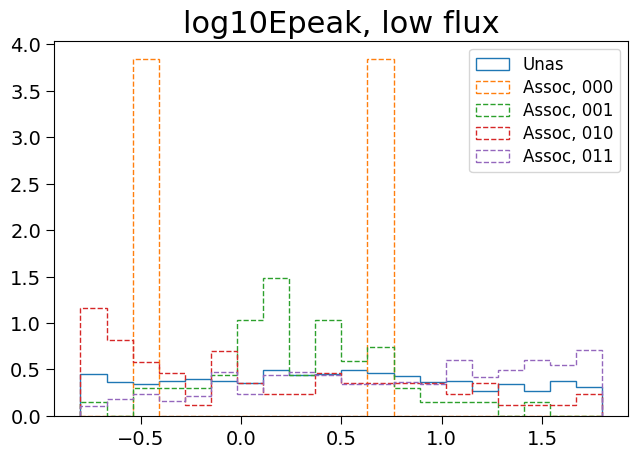

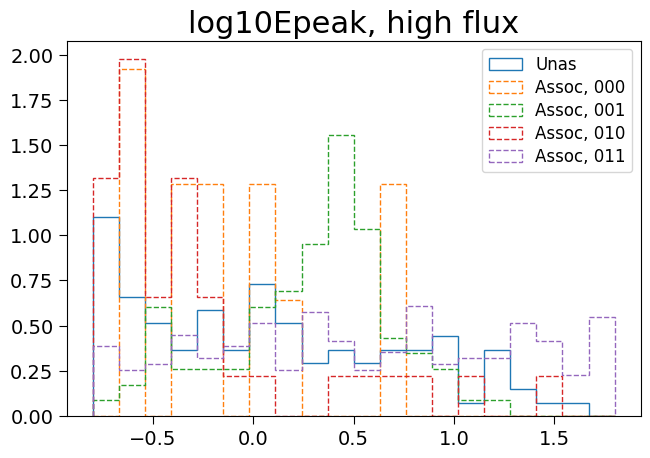

In [187]:
add_fmask = True
plot_all_assoc = False
density = True
if plot_all_assoc:
    clf_masks = {'all': clf_mask}
for cname in top_features:
    xu = {}
    xa = {}
    if add_fmask:
        med_log_flux = np.median(xdf['log10(Energy_Flux100)'][clf_mask & mask])
        fmask = xdf['log10(Energy_Flux100)'] > med_log_flux
        fmask_dict = {'low': ~fmask, 'high': fmask}
        for name, fmask in fmask_dict.items():
            xu[name] = np.array(xdf[cname][unas_mask & mask & fmask], dtype=float)
            for mname, clf_msk in clf_masks.items():
                xa[name + mname] = np.array(xdf[cname][clf_msk & mask & fmask], dtype=float)
    else:
        xu['all'] = np.array(xdf[cname][unas_mask & mask], dtype=float)
        #xa = np.array(xdf[cname][~unas_mask], dtype=float)
        xa['all'] = np.array(xdf[cname][clf_mask & mask], dtype=float)
        pvalue = kstest(xu, xa)[1]
        print(cname, pvalue)
    
    for name in xu.keys():
        pyplot.figure()
        if cname == 'LP_SigCurv':
            bins = np.linspace(0, 20, 21)
        elif cname == 'log10Epeak':
            bins = np.linspace(-0.8, 1.8, 21)
        elif cname == 'LP_index1000MeV':
            bins = np.linspace(-1., 4, 21)
        elif cname == 'LP_beta':
            bins = np.linspace(-0.2, 0.8, 21)
        else:
            bins = 20
        pyplot.hist(xu[name], density=density, 
                    histtype='step', alpha=1, label='Unas', bins=bins)
        if add_fmask:
            for mname, clf_msk in clf_masks.items():
                label_name = label_dict.get(mname, mname)
                pyplot.hist(xa[name+mname], density=density, ls='--',
                            histtype='step', alpha=1, label='Assoc, %s' % label_name, bins=bins)
        else:
            pyplot.hist(xa[name], density=density, ls='--',
                        histtype='step', alpha=1, label='Assoc', bins=bins)
        pyplot.legend()
        title = cname
        if add_fmask:
            title += ', %s flux' % name
        pyplot.title(title)

        if save_plots:
            fn = '%sass_vs_unass_%s_%s.pdf' % (plots_folder, cname, name)
            print('save figure to file: %s' % (fn))
            pyplot.savefig(fn, metadata=fig_meta)
            if copy2tex:
                plots_folder_paper = paper_folder
                fn_paper = fn.replace(plots_folder, plots_folder_paper)
                cmd = 'cp "%s" "%s"' % (fn, fn_paper)
                print(cmd)
                os.system(cmd)

In [188]:
aica = np.zeros(len(nGMMs))
aicu = np.zeros(len(nGMMs))
bica = np.zeros(len(nGMMs))
bicu = np.zeros(len(nGMMs))
nav_gmm = 4

mdlu_dict = {}
mdla_dict = {}

if save_weights or recalculate or (not os.path.isfile(weights_fn)) or test_nGMM:
    print('Calclating weights')
    mdlu_probs_dict = {}
    mdla_probs_dict = {}
        
    for i, nGMM in enumerate(nGMMs):
        print(nGMM)
        cdict['nGMM_w'] = nGMM
        for k in range(nav_gmm):
            print('%i, ' % k, end='')
            # GMM model of assoc and unas sources
            mdla = GaussianMixture(n_components=nGMM, init_params='random', n_init=3, random_state=k);
            #mdla.fit(xdf[top_features][~unas_mask])
            mdla.fit(xdf[top_features][clf_mask])
            mdlu = GaussianMixture(n_components=nGMM, init_params='random', n_init=3, random_state=k);
            mdlu.fit(xdf[top_features][unas_mask])
            logL_u = mdlu.score_samples(xdf[top_features])
            mdlu_probs = np.exp(logL_u) # score_samples - log likelihood for each sample
            logL_a = mdla.score_samples(xdf[top_features])
            mdla_probs = np.exp(logL_a)
            if k == 0:
                mdlu_probs_dict[nGMM] = mdlu_probs / nav_gmm
                mdla_probs_dict[nGMM] = mdla_probs / nav_gmm
            else:
                mdlu_probs_dict[nGMM] += mdlu_probs / nav_gmm
                mdla_probs_dict[nGMM] += mdla_probs / nav_gmm
        mdlu_dict[nGMM] = mdlu
        mdla_dict[nGMM] = mdla
        
        #aica[i] = AIC(logL_a[clf_mask], nGMM, ndim=10)
        #aicu[i] = AIC(logL_u[unas_mask], nGMM, ndim=10)
        aica[i] = mdla.aic(xdf[top_features][clf_mask])
        aicu[i] = mdlu.aic(xdf[top_features][unas_mask])
        bica[i] = mdla.bic(xdf[top_features][clf_mask])
        bicu[i] = mdlu.bic(xdf[top_features][unas_mask])

        # check saving of probabilities for different nGMM
        weights_df = pd.DataFrame(index=xdf.index, columns=['assoc_pdf', 'unas_pdf'], data=0.)
        weights_df['assoc_pdf'] = mdla_probs_dict[nGMM]
        weights_df['unas_pdf'] = mdlu_probs_dict[nGMM]
        if save_weights:
            weights_fn = util.get_weights_fn(cdict)
            print('save weights to file')
            print(weights_fn)
            weights_df.to_csv(weights_fn)
        else:
            print('weights fn test:', util.get_weights_fn(cdict))
    mdlu_probs = mdlu_probs_dict[nGMM_base]
    mdla_probs = mdla_probs_dict[nGMM_base]
            
else:
    weights_df = pd.read_csv(weights_fn, index_col=0)
    mdlu_probs = weights_df['unas_pdf']
    mdla_probs = weights_df['assoc_pdf']


Calclating weights
12
0, 1, 2, 3, save weights to file
../../data_out//weights/weights_4FGL-DR4_no_bcu_spp_all_features_12kernels.csv


In [189]:
samples_u = mdlu.sample(n_samples=len(logL_u))[0]
logL_u_gen = mdlu.score_samples(samples_u)
logL_u = mdlu.score_samples(xdf[top_features][unas_mask])
samples_a = mdla.sample(n_samples=len(logL_a))[0]
logL_a_gen = mdla.score_samples(samples_a)
logL_a = mdla.score_samples(xdf[top_features][clf_mask])
#logL_a_gen = mdlu.sample(n_samples=len(logL_a))

/Users/Dmitry/miniconda3/envs/tf/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but GaussianMixture was fitted with feature names
  warnings.warn(
/Users/Dmitry/miniconda3/envs/tf/lib/python3.10/site-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but GaussianMixture was fitted with feature names
  warnings.warn(


In [190]:
bins = np.arange(-20, 21.1, 1.)
xc = (bins[1:] + bins[:-1]) / 2.
logLu_hist, xbins = np.histogram(logL_u, density=True, bins=bins)
logLu_gen_hist, xbins = np.histogram(logL_u_gen, density=True, bins=bins)
logLa_hist, xbins = np.histogram(logL_a, density=True, bins=bins)
logLa_gen_hist, xbins = np.histogram(logL_a_gen, density=True, bins=bins)

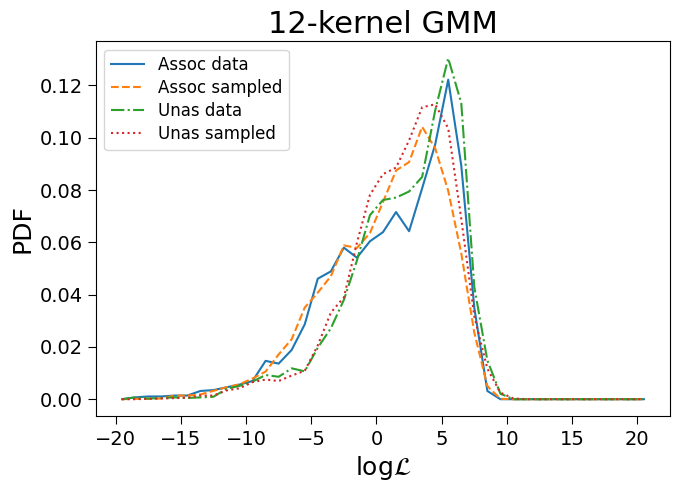

In [191]:
if not test_nGMM:
    pyplot.figure()
    pyplot.plot(xc, logLa_hist, ls='-', label='Assoc data')
    pyplot.plot(xc, logLa_gen_hist, ls='--', label='Assoc sampled')
    pyplot.plot(xc, logLu_hist, ls='-.', label='Unas data')
    pyplot.plot(xc, logLu_gen_hist, ls=':', label='Unas sampled')
    pyplot.legend(loc='upper left')
    pyplot.title('%i-kernel GMM' % nGMM)
    pyplot.ylabel('PDF')
    pyplot.xlabel(r'${\rm log}\cal{L}$')

    if save_plots:
        fn = '%s/logL_PDFs_%iGMMs.pdf' % (plots_folder, nGMM)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if copy2tex:
            plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
            fn_paper = fn.replace(plots_folder, plots_folder_paper)
            cmd = 'cp "%s" "%s"' % (fn, fn_paper)
            print(cmd)
            os.system(cmd)

In [192]:
if test_nGMM:
    yscale = 'linear' # 'log'
    offset = 1000
    pyplot.figure()
    minv = 0
    if yscale == 'log':
        minv = np.min(aica) - offset
    pyplot.plot(nGMMs, aica - minv, ls='-', label='Assoc AIC')
    if yscale == 'log':
        minv = np.min(bica) - offset
    pyplot.plot(nGMMs, bica - minv, ls='--', label='Assoc BIC')
    if yscale == 'log':
        minv = np.min(aicu) - offset
    pyplot.plot(nGMMs, aicu - minv, ls='-.', label='Unas AIC')
    if yscale == 'log':
        minv = np.min(bicu) - offset
    pyplot.plot(nGMMs, bicu - minv, ls=':', label='Unas BIC')
    pyplot.yscale(yscale)
    pyplot.legend()
    pyplot.grid()
    pyplot.xlabel('Number of GMM kernels')
    pyplot.ylabel('AIC or BIC')
    pyplot.ticklabel_format(style='sci', axis='y', scilimits=(-1,2))

    if save_plots and test_nGMM:
        fn = '%s/AIC_BIC_vs_nGMMs.pdf' % (plots_folder)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if copy2tex:
            plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
            fn_paper = fn.replace(plots_folder, plots_folder_paper)
            cmd = 'cp "%s" "%s"' % (fn, fn_paper)
            print(cmd)
            os.system(cmd)

In [193]:
np.argmin(aica), np.argmin(bica), np.argmin(aicu), np.argmin(bicu)

(0, 0, 0, 0)

In [194]:
nGMMs[np.argmin(aica)], nGMMs[np.argmin(bica)], nGMMs[np.argmin(aicu)], nGMMs[np.argmin(bicu)]

(12, 12, 12, 12)

In [195]:
aicu, bicu

(array([-16497.47046543]), array([-10539.71013829]))

In [196]:
np.sum(mdlu_probs < 0.01), np.sum(mdlu_probs > 0.01)

(1104, 6087)

In [197]:
gumask = mdlu_probs > 0.0000001
gamask = mdla_probs > 0.0000001
print(sum(~gumask & unas_mask), sum(~gumask & ~unas_mask))
print(sum(~gamask & unas_mask), sum(~gamask & ~unas_mask))

4 142
16 4


In [ ]:
np.min(mdla_probs), max_sample

In [ ]:
binary = False
#max_sample = 10
sample_ratio = util.get_sample_ratio(mdlu_probs, mdla_probs, binary=binary, max_sample=max_sample)
if binary:
    sample_ratio_bin = sample_ratio
else:
    sample_ratio_bin = util.get_sample_ratio(mdlu_probs, mdla_probs, binary=True, max_sample=max_sample-0.01)

In [ ]:
res = pyplot.hist(sample_ratio[clf_mask], bins=np.linspace(0, max_sample, 2 * max_sample + 1));
pyplot.title('Assoc');

In [ ]:
# Effective number of points
msize = 6
nass = np.sum(clf_mask)
nunas = np.sum(~clf_mask)
step = 3
ms_min = 1
ms_max = ms_min + 6 * step
mss = np.arange(ms_min, ms_max + 1, step)
neff_dict = {'all':np.zeros_like(mss)}
nw_dict = {'all':np.zeros_like(mss)}
clf_masks = {}
sfactor = 1.
for key in tree_cat_dict:
    cls = tree_cat_dict[key]
    clf_masks[key] = util.get_cl_mask(cls, xdf, cname=class_name)
    neff_dict[key] = np.zeros_like(mss)
    nw_dict[key] = np.zeros_like(mss)
for i, ms in enumerate(mss):
    sample_ratio_loc = util.get_sample_ratio(mdlu_probs, mdla_probs, binary=binary, max_sample=ms)
    neff_dict['all'][i] = get_neff(sample_ratio_loc[clf_mask])
    nw_dict['all'][i] = np.sum(sample_ratio_loc[clf_mask]) * sfactor
    for key in tree_cat_dict:
        neff_dict[key][i] = get_neff(sample_ratio_loc[clf_masks[key]])
        nw_dict[key][i] = np.sum(sample_ratio_loc[clf_masks[key]]) * sfactor

nsrc_df = util.nsrc_dict2df(nsrc_dict)
pyplot.figure()
for i, key in enumerate(neff_dict.keys()):
    cls = tree_cat_dict.get(key, 'all')
    ind = np.argmin(np.abs(mss - max_sample))
    neff = neff_dict[key][ind]
    nw = nw_dict[key][ind]
    if cls == 'all':
        nsrc = nass
        label = 'all (%i/%i)' % (neff, nsrc) 
    else:
        nsrc = np.sum([nsrc_dict[cl] for cl in cls])
        label = '%s+ (%i/%i)' % (util.get_max_class(cls, nsrc_df), neff, nsrc)
    p = pyplot.semilogy(mss, neff_dict[key], label=label, ls=lss[i], marker=markers[i], markersize=msize*0.8)
    color = p[0].get_color()
    pyplot.plot(max_sample + 0.3*(i%2), nsrc, color=color, marker=markers[i], markersize=msize)
pyplot.legend(loc='upper right', ncol=2)
pyplot.xlim(ms_min - 1, ms_max + 1)
pyplot.ylim(10, 1.e5)
pyplot.grid()
pyplot.title('Effective sample number')
pyplot.xlabel('Max sample weight')
pyplot.ylabel('Number of sources')

if save_plots:
    fn = '%seffective_sample_number.pdf' % (plots_folder)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if copy2tex:
        plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp "%s" "%s"' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

pyplot.figure()
for i, key in enumerate(neff_dict.keys()):
    cls = tree_cat_dict.get(key, 'all')
    ind = np.argmin(np.abs(mss - max_sample))
    neff = neff_dict[key][ind]
    nw = nw_dict[key][ind]
    if cls == 'all':
        nsrc = nass
        label = 'all (%i/%i)' % (nw, nsrc) 
    else:
        nsrc = np.sum([nsrc_dict[cl] for cl in cls])
        
        label = '%s+ (%i/%i)' % (util.get_max_class(cls, nsrc_df), nw, nsrc)
    p = pyplot.semilogy(mss, nw_dict[key], label=label, ls=lss[i], marker=markers[i], markersize=msize*0.8)
    color = p[0].get_color()
    pyplot.plot(max_sample + 0.5*(i%2 - 0.5), nsrc, color=color, marker=markers[i], markersize=msize)

pyplot.xlabel('Max sample weight')
pyplot.ylabel('Number of sources')
pyplot.legend(loc='lower right', ncol=2)
pyplot.xlim(ms_min - 1, ms_max + 1)
pyplot.ylim(3, 3.e4)
pyplot.grid()
pyplot.title('Sum of sample weights')


if save_plots:
    fn = '%ssample_weights.pdf' % (plots_folder)
    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if copy2tex:
        plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
        fn_paper = fn.replace(plots_folder, plots_folder_paper)
        cmd = 'cp "%s" "%s"' % (fn, fn_paper)
        print(cmd)
        os.system(cmd)

#dneff = -(neff_arr[1:] - neff_arr[:-1])
#ddneff = neff_arr[:-2] + neff_arr[2:] - 2 * neff_arr[1:-1]
#pyplot.figure()
#pyplot.plot(mss[:-1], dneff)
#pyplot.figure()
#pyplot.plot(mss[1:-1], ddneff)
#print(get_neff(sample_ratio[clf_mask]), nass, nunas)
#print(np.sum(sample_ratio[clf_mask] > 4.5))

In [ ]:
pyplot.hist(sample_ratio[unas_mask], bins=np.linspace(0, max_sample, 2 * max_sample + 1));
pyplot.title('Unas');

In [ ]:
nass = sum(clf_mask)
sinds = random.choices(np.arange(len(xdf))[clf_mask], weights=sample_ratio[clf_mask], k=nass)
#wa = sample_ratio[clf_mask]
mss = np.arange(1, 17, 3)
#max_sample = 13

lwe = 1.5

for cname in top_features:
    xu = xdf[cname][unas_mask]
    xa = xdf[cname][clf_mask]
    
    xaw = xdf[cname][sinds]
    #xaw = random.choices(xa, weights=wa, k=len(xu))
    #pvalue = kstest(xu, xa)[1]
    #print(cname, pvalue)
    
    pyplot.figure()
    if cname == 'LP_SigCurv':
        bins = np.linspace(0, 20, 21)
    else:
        bins = 20
    y, xbins = np.histogram(xu, density=True, bins=bins)
    xc = (xbins[1:] + xbins[:-1]) / 2
    pyplot.plot(xc, y, ls='-', lw=lwe, label='Unas')
    
    y, xbins = np.histogram(xa, density=True, bins=xbins)
    pyplot.plot(xc, y, ls='-.', lw=lwe, label='Assoc')
    for ms in mss:
        sample_ratio_loc = util.get_sample_ratio(mdlu_probs, mdla_probs, binary=binary, max_sample=ms)
        wa = sample_ratio_loc[clf_mask]
        y, xbins = np.histogram(xa, density=True, bins=xbins, weights=wa)
        if ms == max_sample:
            ls = '--'
            lw = lwe
        else:
            ls = ':'
            lw = 1
        pyplot.plot(xc, y, ls=ls, lw=lw, label=r'wAssoc ($w \leq %i$)' % ms)
    
    #y, xbins = np.histogram(xaw, density=True, bins=xbins)
    #pyplot.plot(xc, y, ls=':', label='Assoc sampled')

    pyplot.legend()
    #pyplot.title(cname)
    pyplot.xlabel(cname)
    pyplot.ylabel('PDF')
    
    if save_plots:
        fn = '%sass_vs_unass_weighted_%s.pdf' % (plots_folder, cname)
        fn = fn.replace('(', '_')
        fn = fn.replace(')', '')
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if copy2tex and cname in paper_features:
            plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
            fn_paper = fn.replace(plots_folder, plots_folder_paper)
            cmd = 'cp "%s" "%s"' % (fn, fn_paper)
            print(cmd)
            os.system(cmd)


In [ ]:
if test_nGMM:
    for cname in top_features:
        xu = xdf[cname][unas_mask]
        xa = xdf[cname][clf_mask]

        xaw = xdf[cname][sinds]
        #xaw = random.choices(xa, weights=wa, k=len(xu))
        #pvalue = kstest(xu, xa)[1]
        #print(cname, pvalue)

        pyplot.figure()
        if cname == 'LP_SigCurv':
            bins = np.linspace(0, 20, 21)
        else:
            bins = 20
        y, xbins = np.histogram(xu, density=True, bins=bins)
        xc = (xbins[1:] + xbins[:-1]) / 2
        pyplot.plot(xc, y, ls='-', lw=lwe, label='Unas')

        y, xbins = np.histogram(xa, density=True, bins=xbins)
        pyplot.plot(xc, y, ls='-.', lw=lwe, label='Assoc')
        for i, nGMM in enumerate(nGMMs):
            sample_ratio_loc = util.get_sample_ratio(mdlu_probs_dict[nGMM], mdla_probs_dict[nGMM], 
                                                     binary=binary, max_sample=max_sample)
            wa = sample_ratio_loc[clf_mask]
            y, xbins = np.histogram(xa, density=True, bins=xbins, weights=wa)
            ls = lss[i%len(lss)]
            if nGMM == nGMM_base:
                #ls = '--'
                lw = lwe
            else:
                #ls = ':'
                lw = 1
            pyplot.plot(xc, y, ls=ls, lw=lw, label=r'wAssoc ($n = %i$)' % nGMM)

        #y, xbins = np.histogram(xaw, density=True, bins=xbins)
        #pyplot.plot(xc, y, ls=':', label='Assoc sampled')

        pyplot.legend()
        #pyplot.title(cname)
        pyplot.xlabel(cname)
        pyplot.ylabel('PDF')

        if save_plots:
            fn = '%sass_vs_unass_weighted_%s.pdf' % (plots_folder, cname)
            fn = fn.replace('(', '_')
            fn = fn.replace(')', '')
            print('save figure to file: %s' % (fn))
            pyplot.savefig(fn, metadata=fig_meta)
            if copy2tex and cname in paper_features:
                plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
                fn_paper = fn.replace(plots_folder, plots_folder_paper)
                cmd = 'cp "%s" "%s"' % (fn, fn_paper)
                print(cmd)
                os.system(cmd)


In [ ]:
if test_nGMM:
    # calculate the difference of 1D PDFs
    nGMMs_plot = nGMMs[1:9]
    mss = np.arange(1, 17)
    PDF_diff = np.zeros((len(nGMMs_plot), len(mss)))
    PDF_diff_au = 0.
    for cname in top_features:
        xu = xdf[cname][unas_mask]
        xa = xdf[cname][clf_mask]

        if cname == 'LP_SigCurv':
            bins = np.linspace(0, 20, 21)
        else:
            bins = 20
        yu, xbins = np.histogram(xu, density=True, bins=bins)
        ya, xbins = np.histogram(xa, density=True, bins=xbins)
        dx = xbins[1] - xbins[0]
        PDF_diff_au += np.sum(np.abs(yu - ya)) * dx
        #print(dx, sum(yu) * dx)
        for i, nGMM in enumerate(nGMMs_plot):
            for j, ms in enumerate(mss):
                sample_ratio_loc = util.get_sample_ratio(mdlu_probs_dict[nGMM], mdla_probs_dict[nGMM], 
                                                         binary=binary, max_sample=ms)
                wa = sample_ratio_loc[clf_mask]
                yaw, xbins = np.histogram(xa, density=True, bins=xbins, weights=wa)
                PDF_diff[i, j] += np.sum(np.abs(yu - yaw)) * dx

In [ ]:
if test_nGMM:
    #putil.setup_figure_pars()

    # Show all ticks and label them with the respective list entries
    fig, ax = pyplot.subplots()
    im = ax.imshow(PDF_diff, origin='lower', vmax=7, vmin=5)
    arr = mss
    ax.set_xticks(np.arange(len(arr)), labels=arr)
    ax.set_yticks(np.arange(len(nGMMs_plot))[::], labels=nGMMs_plot[::])
    fig.colorbar(im, ax=ax, label='PDF difference squared')
    pyplot.xlabel('Max sample weight')
    pyplot.ylabel('Number of GMM kernels')

    if save_plots and 0:
        fn = '%s/nGMMs_vs_Sample_weight.pdf' % (plots_folder)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if copy2tex:
            plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
            fn_paper = fn.replace(plots_folder, plots_folder_paper)
            cmd = 'cp "%s" "%s"' % (fn, fn_paper)
            print(cmd)
            os.system(cmd)

In [ ]:
if test_nGMM:
    pyplot.figure()
    for i, nGMM in enumerate(nGMMs_plot):
        pyplot.plot(mss, PDF_diff[i], ls=lss[i%len(lss)], label='%i kernels' % nGMM)
    pyplot.legend(ncol=2, fontsize=10)
    pyplot.xlabel('Max sample weight')
    pyplot.ylabel('PDF difference squared')

    if save_plots and test_nGMM and 0:
        fn = '%s/PDF_diff_vs_nGMMs_vs_Sample_weight.pdf' % (plots_folder)
        print('save figure to file: %s' % (fn))
        pyplot.savefig(fn, metadata=fig_meta)
        if copy2tex:
            plots_folder_paper = paper_folder + 'plots/cov_shift_examples/'
            fn_paper = fn.replace(plots_folder, plots_folder_paper)
            cmd = 'cp "%s" "%s"' % (fn, fn_paper)
            print(cmd)
            os.system(cmd)

In [ ]:
mss

In [ ]:
if test_nGMM:
    for i, msi in enumerate(np.argmin(PDF_diff, axis=1)):
        #print(nGMMs[i], mss[msi], PDF_diff[i, msi])
        print(nGMMs_plot[i], mss[msi], PDF_diff[i, :])

In [ ]:
# effective source numbers
sample_ratio_bin_mask = sample_ratio_bin.astype(bool)
#nsrc_dict_w = {cl:np.sum(xdf[class_name][sample_ratio_bin_mask] == cl) for cl in assoc_classes}
nsrc_dict_w = {cl:np.sum((xdf[class_name] == cl)*sample_ratio) for cl in assoc_classes}


In [ ]:
nsrc_dict_w

In [ ]:
nsrc_dict

In [ ]:
os_dict = {key:nsrc_dict_w[key]/nsrc_dict[key] for key in nsrc_dict.keys()}

In [ ]:
os_df = pd.DataFrame(data=os_dict.values(), index=os_dict.keys(), columns=['Oversample'])
os_df = os_df.sort_values('Oversample', ascending=True)

In [ ]:
os_df

In [ ]:
#pl = pyplot.figure()
fig, ax = pyplot.subplots(figsize=(9, 6))
pyplot.plot(os_df, ls='', marker='s')
xticks = ax.get_xticks()
ax.set_xticks(ticks=xticks, labels=os_df.index, rotation=75)
pyplot.xlabel('Class')
pyplot.ylabel('Oversampling')
pyplot.grid()